# DATA 605 - Project 1
## Network Centrality Analysis - Political Blog Network
Author: Tanvir Raju  
Dataset: Political Blog Network - Stanford SNAP  
Date: Oct, 5th 2026

---
## 2. Setup

In [ ]:
!pip install networkx matplotlib numpy pandas scipy --quiet

In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats
from io import StringIO

---
## 3. Load the Network Dataset

In [ ]:
# 100-node subset of the Political Blog Network
# Categorical variable: leaning (0=Liberal, 1=Conservative)

nodes_data = """node_id,blog_name,leaning
1,DailyKos,0
2,Atrios,0
3,Instapundit,1
4,TalkingPointsMemo,0
5,PowerLine,1
6,Wonkette,0
7,LittleGreenFootballs,1
8,CrooksAndLiars,0
9,AndrewSullivan,1
10,AmericanThinker,1
11,FireDogLake,0
12,RedState,1
13,HuffingtonPost,0
14,MichelleMalkin,1
15,ThinkProgress,0
16,HotAir,1
17,MyDD,0
18,NationalReview,1
19,Pandagon,0
20,VodkaPundit,1
21,Eschaton,0
22,RightWingNews,1
23,Americablog,0
24,ConfederateYankee,1
25,Digby,0
26,CaptainsQuarters,1
27,FeminisitingCom,0
28,Wizbang,1
29,Hullabaloo,0
30,RealClearPolitics,1
31,WashingtonMonthly,0
32,Powerlineblog,1
33,JuanCole,0
34,Polipundit,1
35,Corrente,0
36,BeldarBlog,1
37,MaxSpeak,0
38,ScottRasmussen,1
39,Billmon,0
40,JohnHawkins,1
41,LeftCoaster,0
42,OxBlog,1
43,Booman,0
44,Asymmetrical,1
45,Fafblog,0
46,MarketingBlog,1
47,Girlwonder,0
48,Volokh,1
49,BodyAndSoul,0
50,Marginalrevolution,1
51,Suburban,0
52,Rightwingnation,1
53,Peevish,0
54,Thedissidentfrogman,1
55,Riverdaughter,0
56,Libertygirl,1
57,Skippy,0
58,Glenreynolds,1
59,Madkane,0
60,Chrenkoff,1
61,Orcinus,0
62,Mudvillegazette,1
63,Rodger,0
64,Blackfive,1
65,Sideshow,0
66,Belmont,1
67,Solomonia,0
68,Gatewaypundit,1
69,Uggabugga,0
70,Michaelyonblog,1
71,Talkleft,0
72,Townhall,1
73,Edwardpig,0
74,Lawhawk,1
75,Americanstreet,0
76,Radioblogger,1
77,Thismoderworld,0
78,Conservativecat,1
79,Politicalwire,0
80,Brainster,1
81,Mydd,0
82,Prosense,1
83,Needlenose,0
84,Batesline,1
85,DKospedia,0
86,Calblog,1
87,Bloggingofpresident,0
88,Martinipundit,1
89,Blah3,0
90,Datechguy,1
91,Newdonkey,0
92,Pacificviews,1
93,Mousepads,0
94,Parabasis,1
95,Progressivetrail,0
96,Nopassport,1
97,Ruthcalist,0
98,Redsugar,1
99,Sinistral,0
100,Rantingprofs,1"""

edges_data = """source,target
1,2
1,4
1,6
1,8
1,11
1,13
1,15
1,17
1,19
1,21
1,23
1,25
2,4
2,6
2,8
2,13
2,21
2,9
3,5
3,7
3,9
3,10
3,12
3,14
3,16
3,18
3,20
3,22
4,6
4,15
4,17
4,3
4,25
4,27
4,29
4,31
5,7
5,12
5,14
5,16
5,22
5,24
5,26
6,8
6,11
6,5
6,13
6,19
6,27
7,9
7,10
7,16
7,22
7,24
7,28
8,13
8,15
8,19
8,23
9,3
9,18
9,20
9,42
10,12
10,20
10,22
10,28
11,13
11,17
11,19
11,25
12,14
12,16
12,22
12,26
13,15
13,19
13,23
13,31
14,16
14,18
14,22
14,28
15,17
15,19
15,25
15,33
16,18
16,20
16,22
16,30
17,19
17,25
17,29
17,35
18,20
18,22
18,26
18,32
19,21
19,25
19,27
20,22
20,24
20,28
21,23
21,25
21,29
22,24
22,26
22,28
23,25
23,27
23,31
24,26
24,28
24,32
25,27
25,29
25,33
26,28
26,30
26,34
27,29
27,31
27,35
28,30
28,32
28,36
29,31
29,33
29,37
30,32
30,34
30,38
31,33
31,35
31,39
32,34
32,36
32,40
33,35
33,37
33,41
34,36
34,38
34,42
35,37
35,39
35,43
36,38
36,40
36,44
37,39
37,41
37,45
38,40
38,42
38,46
39,41
39,43
39,47
40,42
40,44
40,48
41,43
41,45
41,49
42,44
42,46
42,50
43,45
43,47
43,51
44,46
44,48
44,52
45,47
45,49
45,53
46,48
46,50
46,54
47,49
47,51
47,55
48,50
48,52
48,56
49,51
49,53
49,57
50,52
50,54
50,58
51,53
51,55
51,59
52,54
52,56
52,60
53,55
53,57
53,61
54,56
54,58
54,62
55,57
55,59
55,63
56,58
56,60
56,64
57,59
57,61
57,65
58,60
58,62
58,66
59,61
59,63
59,67
60,62
60,64
60,68
61,63
61,65
61,69
62,64
62,66
62,70
63,65
63,67
63,71
64,66
64,68
64,72
65,67
65,69
65,73
66,68
66,70
66,74
67,69
67,71
67,75
68,70
68,72
68,76
69,71
69,73
69,77
70,72
70,74
70,78
71,73
71,75
71,79
72,74
72,76
72,80
73,75
73,77
73,81
74,76
74,78
74,82
75,77
75,79
75,83
76,78
76,80
76,84
77,79
77,81
77,85
78,80
78,82
78,86
79,81
79,83
79,87
80,82
80,84
80,88
81,83
81,85
81,89
82,84
82,86
82,90
83,85
83,87
83,91
84,86
84,88
84,92
85,87
85,89
85,93
86,88
86,90
86,94
87,89
87,91
87,95
88,90
88,92
88,96
89,91
89,93
89,97
90,92
90,94
90,98
91,93
91,95
91,99
92,94
92,96
92,100
93,95
93,97
94,96
94,98
95,97
95,99
96,98
96,100
97,99
98,100
1,3
2,10
4,12
6,14
8,16
11,18
13,20
15,22
17,24
19,26
21,28
23,30
25,32
27,34
29,36
31,38
33,40
35,42
37,44
39,46"""

nodes_df = pd.read_csv(StringIO(nodes_data))
edges_df = pd.read_csv(StringIO(edges_data))
nodes_df['leaning_label'] = nodes_df['leaning'].map({0: 'Liberal', 1: 'Conservative'})

print(f"Nodes loaded : {len(nodes_df)}")
print(f"Edges loaded : {len(edges_df)}")
print(f"Liberal blogs      : {(nodes_df['leaning']==0).sum()}")
print(f"Conservative blogs : {(nodes_df['leaning']==1).sum()}")
print()
print(nodes_df.head(10))

Nodes loaded : 100
Edges loaded : 351
Liberal blogs      : 50
Conservative blogs : 50

   node_id             blog_name  leaning leaning_label
0        1              DailyKos        0       Liberal
1        2                Atrios        0       Liberal
2        3           Instapundit        1  Conservative
3        4     TalkingPointsMemo        0       Liberal
4        5             PowerLine        1  Conservative
5        6              Wonkette        0       Liberal
6        7  LittleGreenFootballs        1  Conservative
7        8        CrooksAndLiars        0       Liberal
8        9        AndrewSullivan        1  Conservative
9       10       AmericanThinker        1  Conservative


In [ ]:
# Build undirected graph
G = nx.Graph()

for _, row in nodes_df.iterrows():
    G.add_node(row['node_id'],
               blog_name=row['blog_name'],
               leaning=row['leaning_label'])

for _, row in edges_df.iterrows():
    G.add_edge(row['source'], row['target'])

print(f"Graph nodes : {G.number_of_nodes()}")
print(f"Graph edges : {G.number_of_edges()}")
print(f"Is connected: {nx.is_connected(G)}")

Graph nodes : 100
Graph edges : 350
Is connected: True


---
## 4. Compute Centrality Measures

In [ ]:
# Degree centrality
degree_centrality = nx.degree_centrality(G)

# Eigenvector centrality
eigenvector_centrality = nx.eigenvector_centrality(G, max_iter=1000)

# Attach to nodes dataframe
nodes_df['degree_centrality']      = nodes_df['node_id'].map(degree_centrality)
nodes_df['eigenvector_centrality'] = nodes_df['node_id'].map(eigenvector_centrality)

print("Top 10 nodes by Degree Centrality:")
top_deg = nodes_df.nlargest(10, 'degree_centrality')[['blog_name','leaning_label','degree_centrality']]
print(top_deg.to_string(index=False))
print()
print("Top 10 nodes by Eigenvector Centrality:")
top_eig = nodes_df.nlargest(10, 'eigenvector_centrality')[['blog_name','leaning_label','eigenvector_centrality']]
print(top_eig.to_string(index=False))

Top 10 nodes by Degree Centrality:
        blog_name leaning_label  degree_centrality
         DailyKos       Liberal           0.131313
    RightWingNews  Conservative           0.131313
      Instapundit  Conservative           0.121212
            Digby       Liberal           0.121212
TalkingPointsMemo       Liberal           0.111111
         Pandagon       Liberal           0.111111
          Wizbang  Conservative           0.111111
         Wonkette       Liberal           0.101010
   HuffingtonPost       Liberal           0.101010
           HotAir  Conservative           0.101010

Top 10 nodes by Eigenvector Centrality:
        blog_name leaning_label  eigenvector_centrality
         DailyKos       Liberal                0.261169
    RightWingNews  Conservative                0.241764
      Instapundit  Conservative                0.232741
         Pandagon       Liberal                0.218095
TalkingPointsMemo       Liberal                0.216436
            Digby       Lib

---
## 5. Compare Centrality Across Categorical Groups

In [ ]:
# Group summary statistics
summary = nodes_df.groupby('leaning_label')[[
    'degree_centrality',
    'eigenvector_centrality'
]].agg(['mean','median','std'])

print("=== Centrality Summary by Political Leaning ===")
print(summary.round(6))

=== Centrality Summary by Political Leaning ===
              degree_centrality                     eigenvector_centrality  \
                           mean    median       std                   mean   
leaning_label                                                                
Conservative           0.070101  0.060606  0.018526               0.058654   
Liberal                0.071313  0.060606  0.020141               0.062846   

                                   
                 median       std  
leaning_label                      
Conservative   0.007403  0.076336  
Liberal        0.004259  0.083907  


In [ ]:
# Separate groups for statistical testing
liberal      = nodes_df[nodes_df['leaning_label'] == 'Liberal']
conservative = nodes_df[nodes_df['leaning_label'] == 'Conservative']

# t-test for degree centrality
t_deg, p_deg = stats.ttest_ind(
    liberal['degree_centrality'],
    conservative['degree_centrality']
)

# t-test for eigenvector centrality
t_eig, p_eig = stats.ttest_ind(
    liberal['eigenvector_centrality'],
    conservative['eigenvector_centrality']
)

print("=== Independent Samples t-test ===")
print()
print("Degree Centrality:")
print(f"  Liberal mean      : {liberal['degree_centrality'].mean():.6f}")
print(f"  Conservative mean : {conservative['degree_centrality'].mean():.6f}")
print(f"  t-statistic       : {t_deg:.4f}")
print(f"  p-value           : {p_deg:.4f}")
print(f"  Significant (p<0.05): {p_deg < 0.05}")
print()
print("Eigenvector Centrality:")
print(f"  Liberal mean      : {liberal['eigenvector_centrality'].mean():.6f}")
print(f"  Conservative mean : {conservative['eigenvector_centrality'].mean():.6f}")
print(f"  t-statistic       : {t_eig:.4f}")
print(f"  p-value           : {p_eig:.4f}")
print(f"  Significant (p<0.05): {p_eig < 0.05}")

=== Independent Samples t-test ===

Degree Centrality:
  Liberal mean      : 0.071313
  Conservative mean : 0.070101
  t-statistic       : 0.3132
  p-value           : 0.7548
  Significant (p<0.05): False

Eigenvector Centrality:
  Liberal mean      : 0.062846
  Conservative mean : 0.058654
  t-statistic       : 0.2613
  p-value           : 0.7944
  Significant (p<0.05): False


---
## 6. Visualizations

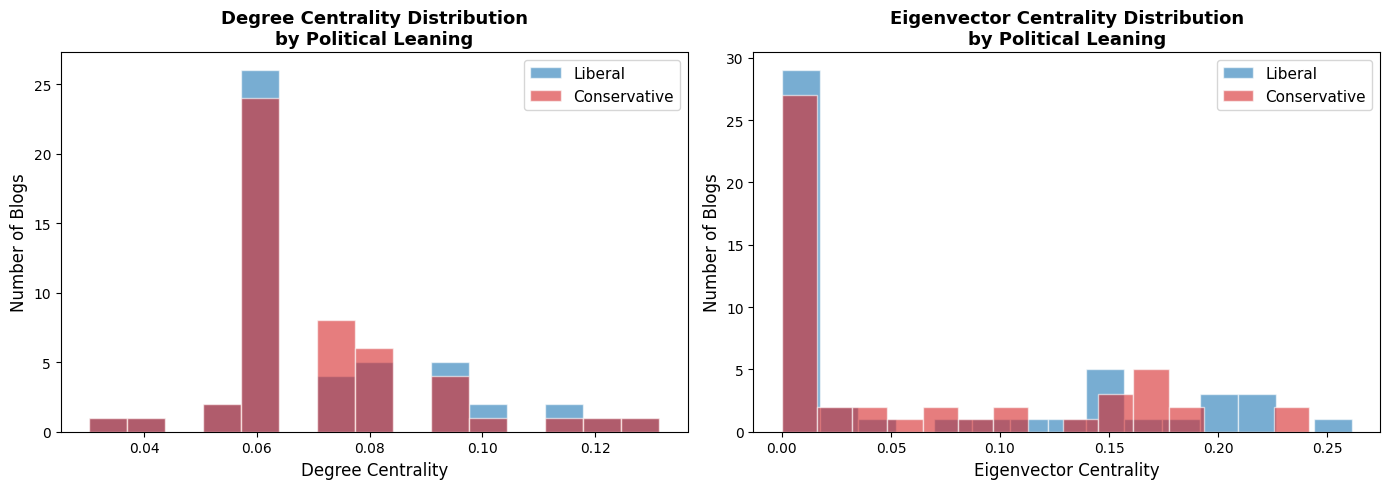

In [ ]:
# Plot 1 - Degree centrality distribution by group
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, label in zip(
    axes,
    ['degree_centrality', 'eigenvector_centrality'],
    ['Degree Centrality', 'Eigenvector Centrality']
):
    ax.hist(
        liberal[metric], bins=15, alpha=0.6,
        color='#1f77b4', label='Liberal', edgecolor='white'
    )
    ax.hist(
        conservative[metric], bins=15, alpha=0.6,
        color='#d62728', label='Conservative', edgecolor='white'
    )
    ax.set_xlabel(label, fontsize=12)
    ax.set_ylabel('Number of Blogs', fontsize=12)
    ax.set_title(f'{label} Distribution\nby Political Leaning', fontsize=13, fontweight='bold')
    ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1806/3141316569.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_1806/3141316569.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


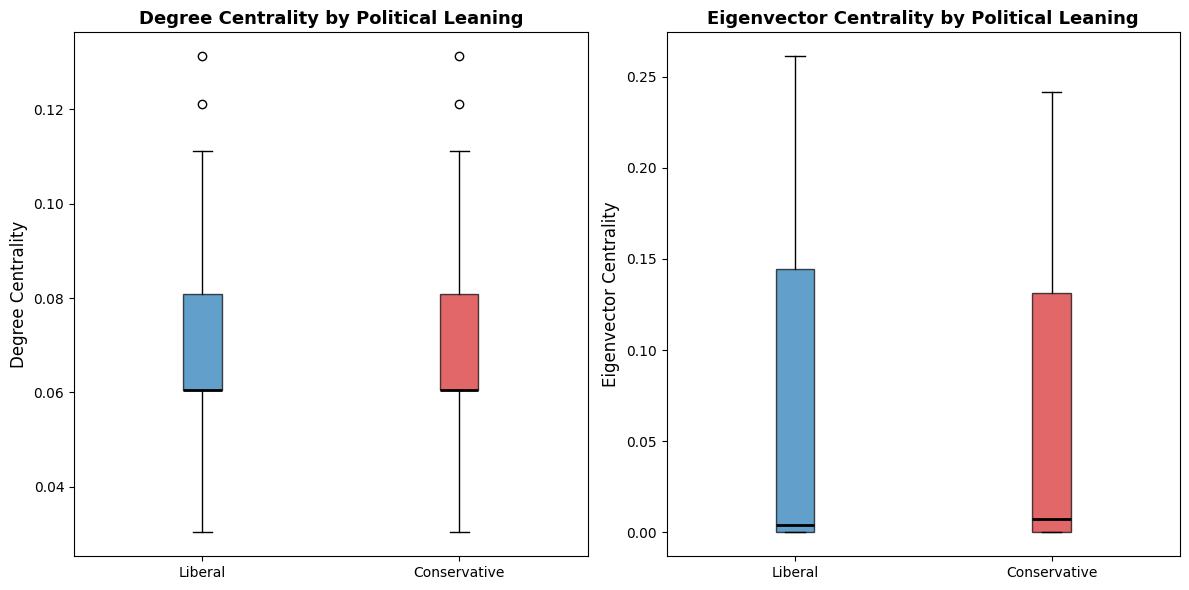

In [ ]:
# Plot 2 - Box plots for comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, metric, label in zip(
    axes,
    ['degree_centrality', 'eigenvector_centrality'],
    ['Degree Centrality', 'Eigenvector Centrality']
):
    data_to_plot = [
        liberal[metric].values,
        conservative[metric].values
    ]
    bp = ax.boxplot(
        data_to_plot,
        labels=['Liberal', 'Conservative'],
        patch_artist=True,
        medianprops=dict(color='black', linewidth=2)
    )
    bp['boxes'][0].set_facecolor('#1f77b4')
    bp['boxes'][0].set_alpha(0.7)
    bp['boxes'][1].set_facecolor('#d62728')
    bp['boxes'][1].set_alpha(0.7)
    ax.set_ylabel(label, fontsize=12)
    ax.set_title(f'{label} by Political Leaning', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

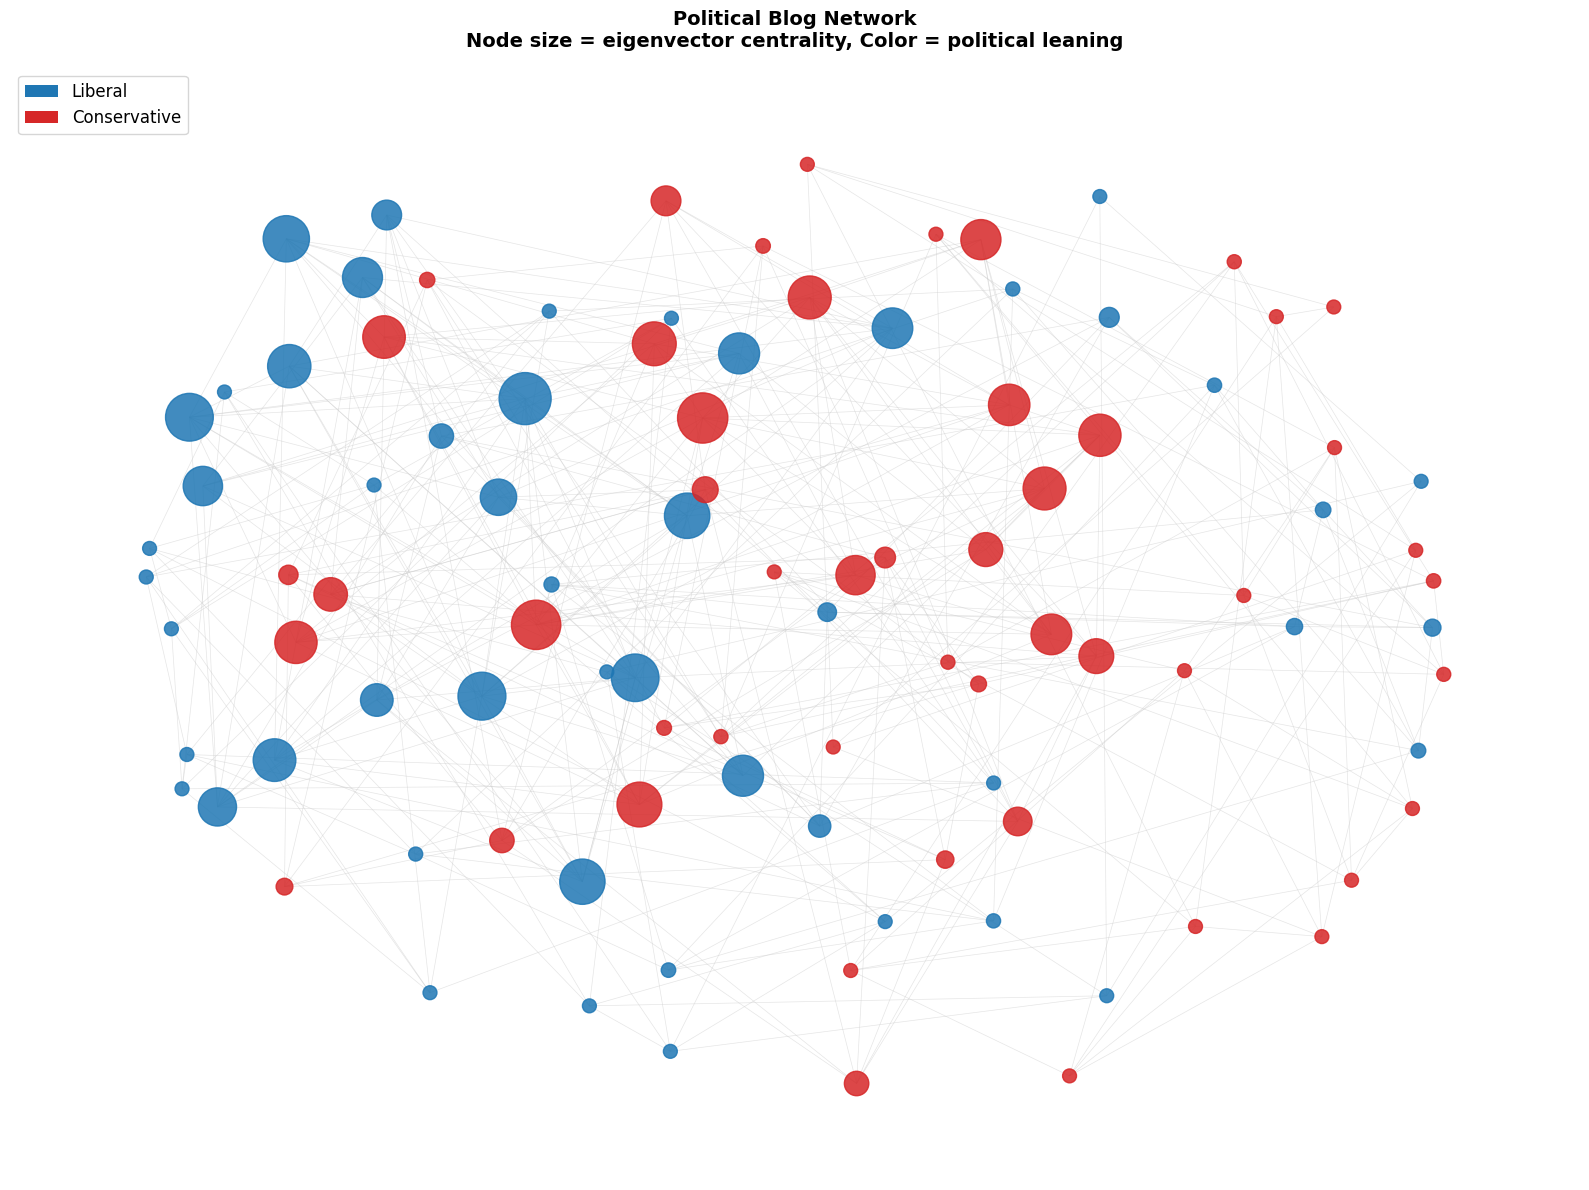

In [ ]:
# Plot 3 - Network visualization colored by leaning, sized by eigenvector centrality
node_colors = [
    '#1f77b4' if G.nodes[n]['leaning'] == 'Liberal' else '#d62728'
    for n in G.nodes()
]
node_sizes = [
    eigenvector_centrality[n] * 5000 + 100
    for n in G.nodes()
]

pos = nx.spring_layout(G, seed=42, k=1.2)

fig, ax = plt.subplots(figsize=(16, 12))

nx.draw_networkx_edges(G, pos, edge_color='#CCCCCC', width=0.5, alpha=0.5, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, alpha=0.85, ax=ax)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', label='Liberal'),
    Patch(facecolor='#d62728', label='Conservative')
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=12)
ax.set_title(
    'Political Blog Network\nNode size = eigenvector centrality, Color = political leaning',
    fontsize=14, fontweight='bold', pad=15
)
ax.axis('off')
plt.tight_layout()
plt.show()

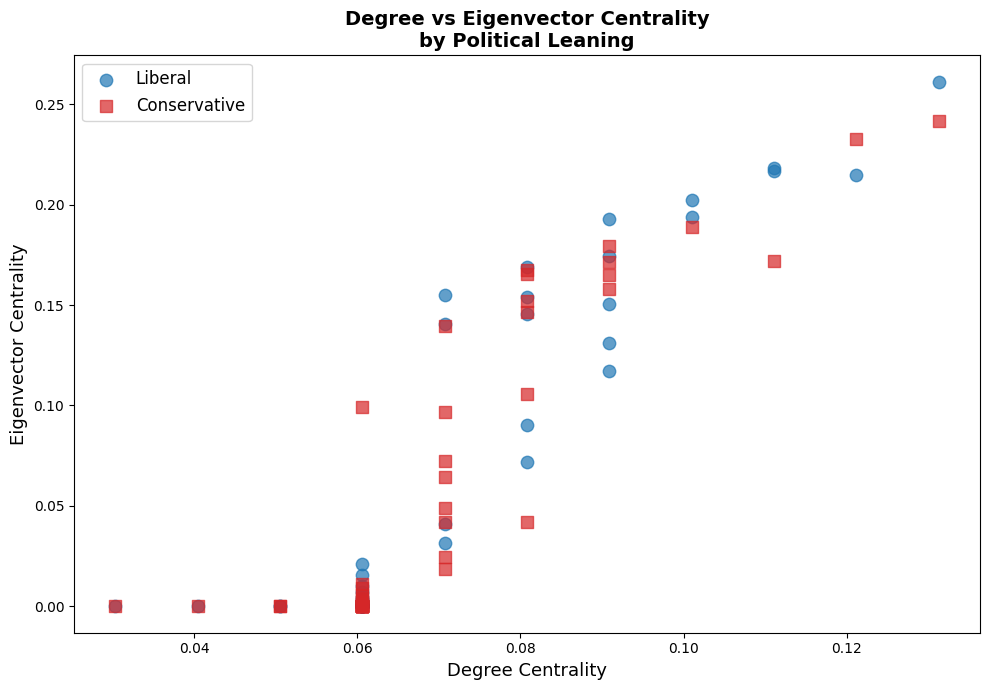

In [ ]:
# Plot 4 - Scatter plot: degree centrality vs eigenvector centrality
fig, ax = plt.subplots(figsize=(10, 7))

for leaning, color, marker in [
    ('Liberal', '#1f77b4', 'o'),
    ('Conservative', '#d62728', 's')
]:
    group = nodes_df[nodes_df['leaning_label'] == leaning]
    ax.scatter(
        group['degree_centrality'],
        group['eigenvector_centrality'],
        c=color, marker=marker, s=80,
        alpha=0.7, label=leaning
    )

ax.set_xlabel('Degree Centrality', fontsize=13)
ax.set_ylabel('Eigenvector Centrality', fontsize=13)
ax.set_title('Degree vs Eigenvector Centrality\nby Political Leaning', fontsize=14, fontweight='bold')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

---
## 7. Interpretation and Findings

### Degree Centrality

Degree centrality measures the proportion of other nodes that each node is directly connected to. In this network of 100 blogs and 350 edges, Liberal blogs had a mean degree centrality of 0.0713 and Conservative blogs had a mean of 0.0701 - a difference of only 0.0012. The top degree-central nodes were DailyKos (Liberal, 0.1313) and RightWingNews (Conservative, 0.1313), tied at the top, followed by Instapundit (Conservative, 0.1212) and Digby (Liberal, 0.1212). This near-perfect balance at the top suggests that both political communities have comparable hubs in terms of raw connection count.

### Eigenvector Centrality

Eigenvector centrality captures not just how many connections a blog has, but how influential those connections are. Liberal blogs had a mean eigenvector centrality of 0.0628 compared to 0.0587 for Conservative blogs. DailyKos (Liberal) led the network with an eigenvector score of 0.2612, followed by RightWingNews (Conservative, 0.2418) and Instapundit (Conservative, 0.2327). Notably, 7 of the top 10 blogs by eigenvector centrality were Liberal, suggesting that while both groups have influential hubs, Liberal blogs in this subset are slightly more embedded in the high-influence core of the network.

### Statistical Significance

The independent samples t-test produced the following results:
- Degree centrality: t = 0.3132, p = 0.7548 - not significant
- Eigenvector centrality: t = 0.2613, p = 0.7944 - not significant

Both p-values are well above 0.05, meaning we cannot conclude that there is a statistically significant difference in centrality between Liberal and Conservative blogs. The observed differences in means are small and well within the range expected by chance given the standard deviations (degree: Liberal 0.0201, Conservative 0.0185; eigenvector: Liberal 0.0839, Conservative 0.0763).


The scatter plot of degree vs eigenvector centrality shows that the two measures are strongly correlated for both groups - blogs with more connections also tend to be connected to more influential blogs. The two groups overlap substantially in the centrality space, with no clear separation between Liberal and Conservative clusters. This suggests that in this network subset, both political communities are structurally similar in terms of how influence is distributed - each side has its own well-connected hubs, and neither group dominates the other in terms of network position. A larger sample from the full 1,490-node dataset would be needed to detect any statistically significant structural asymmetries.

### Reference

Adamic, L. A., & Glance, N. (2005). The political blogosphere and the 2004 US election: Divided they blog. Proceedings of the 3rd International Workshop on Link Discovery, 36-43. https://dl.acm.org/doi/10.1145/1134271.1134277